# Modèle français + kirundi : entraînement LOCAL (GPU NVIDIA)

Même notebook que `entrainement_colab.ipynb`, mais sur **cette machine** (T600, 4 Go).
Tout est écrit dans `A_METTRE_DANS_DRIVE/` et les configs viennent de `configs/local/`.
Guide complet : `README_LOCAL.md`.

**Avant de commencer** : chargeur branché, `powerprofilesctl set performance`, noyau Jupyter
**« Python (modele_train) »** choisi en haut à droite.

| Étape | Ce qui se passe | Durée (T600, estimation) |
|---|---|---|
| 0 | Vérifier le GPU, les dossiers, où on en est, courbe de loss | 1 min |
| 1, 2 | Données et tokenizer : déjà là, sautés | secondes |
| 3 | Phase A (14M) | 3 à 8 h |
| 4 | Agrandir 14M -> 122M | 1 min |
| 5 | Phase B (122M) | 1 à 2 jours |
| 6 | Phase D (questions / réponses) | 4 à 8 h |
| 7 | Tests | 20 min |
| 8 | Essayer le modèle | |

**Si tu fermes l'onglet du navigateur**, l'entraînement continue (le noyau tourne toujours) ;
seul l'affichage est perdu : rouvre le notebook et lance la cellule 0.4 (courbe) ou lis le journal.
**Si le noyau redémarre ou si tu l'arrêtes** (carré ■), l'entraînement s'arrête :
relance l'étape 0 puis la cellule de la phase, elle **reprend** au dernier point sauvegardé.

## Étape 0 : préparer

In [16]:
# 0.1  Vérifier le GPU
import torch
print("PyTorch", torch.__version__, "| GPU :", torch.cuda.is_available())
assert torch.cuda.is_available(), "Pas de GPU : choisis le noyau 'Python (modele_train)' (voir README_LOCAL.md)"
print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} Go")
!nvidia-smi --query-gpu=name,memory.used,memory.total,temperature.gpu,power.draw --format=csv

PyTorch 2.15.0+cu132 | GPU : True
NVIDIA T600 Laptop GPU 3.6 Go
name, memory.used [MiB], memory.total [MiB], temperature.gpu, power.draw [W]
NVIDIA T600 Laptop GPU, 8 MiB, 4096 MiB, 53, 2.88 W


In [18]:
# 0.2  Les dossiers utilisés partout (dans A_METTRE_DANS_DRIVE/, même forme que Drive)
import os

# Le dossier du dépôt = celui du notebook (lance Jupyter depuis modele_train/).
CODE = os.path.abspath(".") if os.path.exists("train.py") else os.path.expanduser("~/Documents/modele_train")
def aller_au_code():
    if not os.path.exists(f"{CODE}/train.py"):
        raise SystemExit("train.py introuvable dans " + CODE + " : ouvre Jupyter depuis le dossier modele_train.")
    os.chdir(CODE)
aller_au_code()
print("Dossier de travail :", os.getcwd())

RACINE  = f"{CODE}/A_METTRE_DANS_DRIVE"
SOURCES = f"{RACINE}/sources"          # bible_kirundi.db, bible_francais.db
D       = f"{RACINE}/donnees"          # données générées
QR      = f"{D}/qr"                    # questions / réponses (phase D)
M       = f"{RACINE}/modele"           # modèles
for d in (D, QR, M, f"{M}/journaux"):
    os.makedirs(d, exist_ok=True)
# Vérification : tout doit être "OK" avant de continuer
for chemin in (f"{D}/conjugaison_fr", f"{D}/conjugaison_rn", f"{D}/grammaire_rn", f"{D}/bible",
               f"{D}/cours", f"{D}/lexique_rn", f"{D}/fsi_rn", f"{QR}/cours.jsonl", f"{M}/tokenizer_fr_rn"):
    print(("OK      " if os.path.exists(chemin) else "MANQUANT"), chemin)

def fait(chemin):
    """True si une étape est déjà finie (pour ne pas la refaire après une coupure)."""
    return os.path.exists(chemin)

def verifier(chemin, etape):
    """Arrête le notebook avec un message clair si une étape n'a pas produit son résultat."""
    if os.path.exists(chemin):
        print(f"OK : {etape} terminée -> {chemin}")
        return
    nom = etape.split()[-1]
    raise SystemExit(
        f"ÉCHEC : {etape} n'a pas produit {chemin}.\n"
        f"Regarde la fin du journal : {M}/journaux/{nom}.txt (ou la sortie de la cellule).\n"
        f"Ne passe PAS à l'étape suivante : corrige d'abord, puis relance cette cellule.")

def meilleur_modele():
    """Le modèle le plus avancé qui existe : phase D, sinon B, sinon A."""
    for ph in ("phaseD", "phaseB", "phaseA"):
        for sous in ("finale", "meilleure"):
            if os.path.exists(f"{M}/{ph}/{sous}/config.json"):
                return f"{M}/{ph}/{sous}"
    raise SystemExit("Aucun modèle entraîné trouvé dans " + M + " : lance d'abord la phase A (étape 3).")

# Moins de "CUDA out of memory" sur 4 Go ; pas de mise en veille pendant l'entraînement.
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
SANS_VEILLE = "systemd-inhibit --what=sleep:idle --why=entrainement"
FILTRE = "grep --line-buffered -vE 'it/s\\]|examples/s'"

Dossier de travail : /home/bienvenu/Documents/modele_train
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/conjugaison_fr
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/conjugaison_rn
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/grammaire_rn
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/bible
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/cours
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/lexique_rn
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/fsi_rn
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/qr/cours.jsonl
OK       /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/modele/tokenizer_fr_rn


In [19]:
# 0.3  OÙ EN SUIS-JE ?  (à lancer à tout moment, surtout après une erreur ou une coupure)
etapes = [("Phase A", f"{M}/phaseA/finale"), ("Agrandissement", f"{M}/grand_init"),
          ("Phase B", f"{M}/phaseB/finale"), ("Phase D", f"{M}/phaseD/finale")]
for nom, chemin in etapes:
    reprise = os.path.exists(chemin.replace("finale", "derniere"))
    etat = "FINIE" if os.path.exists(chemin) else ("en cours (reprise possible)" if reprise else "pas commencée")
    print(f"{nom:15s} : {etat}")
print()
for ph in ("phaseA", "phaseB", "phaseD"):
    j = f"{M}/journaux/{ph}.txt"
    if os.path.exists(j):
        print(f"===== fin de {j}")
        !tail -n 15 "$j"


Phase A         : pas commencée
Agrandissement  : pas commencée
Phase B         : pas commencée
Phase D         : pas commencée



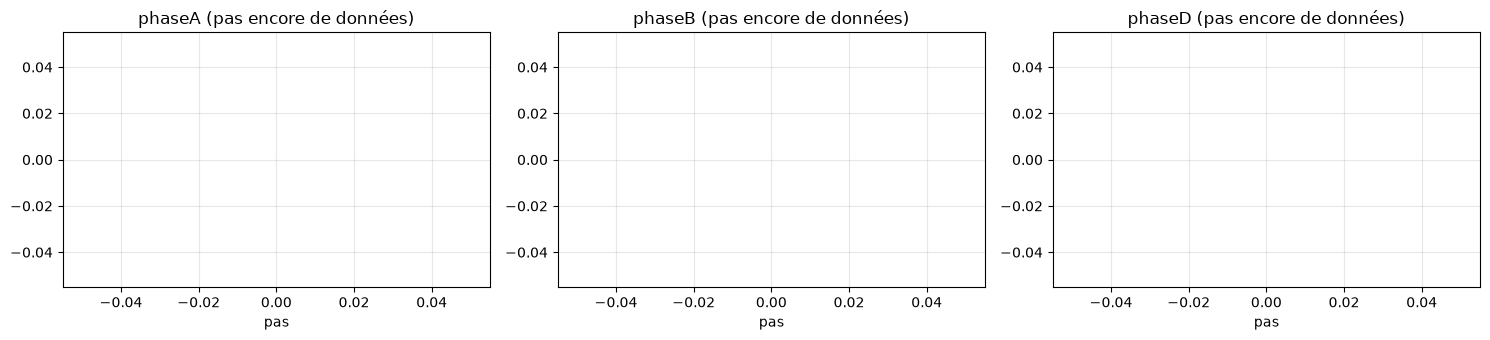

utilization.gpu [%], memory.used [MiB], memory.total [MiB], temperature.gpu, power.draw [W]
0 %, 8 MiB, 4096 MiB, 53, 2.85 W


In [20]:
# 0.4  COURBE DE LA LOSS (relance cette cellule quand tu veux, même pendant l'entraînement,
#      depuis un 2e onglet du même notebook ou après avoir rouvert le navigateur)
import re, matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, ph in zip(axes, ("phaseA", "phaseB", "phaseD")):
    j = f"{M}/journaux/{ph}.txt"
    pas, loss, pas_ev, loss_ev = [], [], [], []
    if os.path.exists(j):
        dernier = 0
        for ligne in open(j, encoding="utf-8", errors="ignore"):
            m = re.search(r"pas (\d+)/\d+ \| loss ([\d.]+)", ligne)
            if m:
                dernier = int(m.group(1)); pas.append(dernier); loss.append(float(m.group(2)))
            m = re.search(r"ÉVALUATION \| loss ([\d.]+)", ligne)
            if m:
                pas_ev.append(dernier); loss_ev.append(float(m.group(1)))
    ax.plot(pas, loss, label="entraînement")
    ax.plot(pas_ev, loss_ev, "o-", label="évaluation")
    ax.set_title(ph + ("" if pas else " (pas encore de données)")); ax.set_xlabel("pas"); ax.grid(alpha=.3)
    if pas: ax.legend()
plt.tight_layout(); plt.show()
!nvidia-smi --query-gpu=utilization.gpu,memory.used,memory.total,temperature.gpu,power.draw --format=csv

## Étape 1 : générer les données

Chaque script écrit des fichiers `.txt` (phase A et B) et `.jsonl` (questions / réponses, phase D).
Les éléments réservés aux **tests** (10 % des phrases traduites, 5 % des verbes) sont **exclus** automatiquement (voir `separation.py`).

In [21]:
aller_au_code()
# 1.1  Français : conjugaison de 7 015 verbes, 12 temps
if not fait(f"{D}/conjugaison_fr"):
    # Seulement si les données manquent : outils de génération (sans casser numpy)
    !pip install -q -r requirements-donnees.txt && pip install -q --no-deps mlconjug3
    !python gen_conjugaison_fr.py --sortie $D/conjugaison_fr --sft $QR/conjugaison_fr.jsonl

In [22]:
aller_au_code()
# 1.2  Kirundi : livre FSI (domaine public, téléchargé automatiquement)
if not fait(f"{D}/fsi_rn/fsi_rn.txt"):
    !pip install -q -r requirements-donnees.txt
    !python extraire_fsi.py --sortie $D/fsi_rn

In [23]:
aller_au_code()
# 1.3  Bible kirundi + français (bases SQLite), passages alignés, part de 25 %
if not fait(f"{D}/bible/bible_bilingue_25.txt"):
    !python extraire_bible_db.py --rn $SOURCES/bible_kirundi.db --fr $SOURCES/bible_francais.db \
        --sortie $D/bible --sft $QR/traduction_bible.jsonl

In [24]:
aller_au_code()
# 1.4  Lexique français <-> kirundi (ta liste de verbes)
#      On travaille sur des COPIES des listes de verbes : les fichiers du dépôt ne changent pas.
if not fait(f"{D}/lexique_rn/lexique_rn.txt"):
    !tail -n +2 $D/bible/mots_bible_rn.tsv | cut -f1 > /tmp/modele_train_mots.tsv
    !cut -f1 $D/fsi_rn/mots_frequents.tsv >> /tmp/modele_train_mots.tsv
    !cp data/verbes_rn.tsv /tmp/modele_train_verbes_copie.tsv
    !python importer_dictionnaire.py --mots /tmp/modele_train_mots.tsv --verbes /tmp/modele_train_verbes_copie.tsv \
        --a_completer /tmp/modele_train_a_completer.tsv --sortie $D/lexique_rn --sft $QR/lexique_rn.jsonl

In [25]:
aller_au_code()
# 1.5  Cours de Cox : phrases traduites par une experte (+ tests mis de côté)
if not fait(f"{D}/cours/cours_bilingue.txt"):
    !python combiner_cours.py --resultats data/cours_resultats --sortie $D/cours --sft $QR/cours.jsonl

In [26]:
aller_au_code()
# 1.6  Kirundi : conjugaison (3 478 verbes, 14 temps), accords (classes), pronoms objets, subordonnées
if not fait(f"{D}/conjugaison_rn"):
    !python gen_conjugaison_rn.py --sortie $D/conjugaison_rn --sft $QR/conjugaison_rn.jsonl
if not fait(f"{D}/grammaire_rn/accords_rn_001.txt"):
    !python gen_accords_rn.py --sortie $D/grammaire_rn --sft $QR/accords_rn.jsonl
if not fait(f"{D}/grammaire_rn/syntaxe_rn_001.txt"):
    !python gen_syntaxe_rn.py --sortie $D/grammaire_rn --sft $QR/syntaxe_rn.jsonl

In [27]:
aller_au_code()
# 1.7  Le jeu de tests (568 questions) et le bilan des données
#      tests/tests.jsonl est déjà dans le dépôt : on ne le refait que s'il manque
#      (il faut alors mlconjug3, outil de génération, installé SANS ses dépendances).
if not fait("tests/tests.jsonl"):
    !pip install -q -r requirements-donnees.txt && pip install -q --no-deps mlconjug3
    !python construire_tests.py 2>&1 | tee $M/journaux/donnees.txt
else:
    !echo "Tests déjà prêts : $(wc -l < tests/tests.jsonl) questions dans tests/tests.jsonl" | tee $M/journaux/donnees.txt
!du -sh $D/* | sort -h | tee -a $M/journaux/donnees.txt
!wc -l $QR/*.jsonl

Tests déjà prêts : 568 questions dans tests/tests.jsonl
36K	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/lexique_rn
92K	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/cours
524K	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/fsi_rn
5.9M	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/grammaire_rn
6.1M	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/conjugaison_rn
21M	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/conjugaison_fr
23M	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/bible
33M	/home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/qr
   10843 /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/qr/accords_rn.jsonl
  107674 /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/qr/conjugaison_fr.jsonl
   47518 /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/donnees/qr/conjugaison_rn.jsonl
    2200 /ho

## Étape 2 : le tokenizer

Créé **une seule fois**, sur **toutes** les données. Ensuite, il ne doit plus jamais changer
(sinon le modèle ne reconnaît plus ses propres numéros).

In [28]:
aller_au_code()
if not fait(f"{M}/tokenizer_fr_rn"):
    !python train_tokenizer.py --source "$D/**/*.txt=1" --taille_vocab 24000 --sortie $M/tokenizer_fr_rn

## Étape 3 : phase A (petit modèle, 14M)

Le modèle apprend les morceaux de mots et les règles simples. Surveille deux chiffres :
- la **loss** doit descendre ;
- les **phrases d'exemple** affichées à chaque évaluation doivent devenir du vrai français / kirundi.

In [29]:
aller_au_code()
if not fait(f"{M}/phaseA/finale"):
    !$SANS_VEILLE python -u train.py --config configs/local/phaseA.yaml 2>&1 | $FILTRE | tee -a $M/journaux/phaseA.txt
verifier(f"{M}/phaseA/finale", "phaseA")

[12:22:57]  Nouvelle table de mots : 50304 -> 24000
[12:22:57]  Modèle chargé : 7.3 millions de paramètres
[12:22:58]  Source A_METTRE_DANS_DRIVE/donnees/conjugaison_fr/*.txt : 107683 exemples x 1
[12:22:59]  Source A_METTRE_DANS_DRIVE/donnees/conjugaison_rn/*.txt : 63694 exemples x 1
[12:22:59]  Source A_METTRE_DANS_DRIVE/donnees/grammaire_rn/*.txt : 17256 exemples x 2
[12:22:59]  Source A_METTRE_DANS_DRIVE/donnees/lexique_rn/*.txt : 49 exemples x 3
[12:23:00]  Source A_METTRE_DANS_DRIVE/donnees/cours/*.txt : 184 exemples x 3
[12:23:08]  Entraînement : 39529 exemples | Évaluation : 400
[12:23:08]  Début : 618 pas au total, 2 époque(s)
[12:26:44]  époque 1 | pas 50/618 | loss 8.798 | lr 1.00e-04 | 4.32 s/pas
[12:29:26]  époque 1 | pas 100/618 | loss 4.150 | lr 2.00e-04 | 3.25 s/pas
[12:32:09]  époque 1 | pas 150/618 | loss 2.648 | lr 3.00e-04 | 3.26 s/pas
[12:34:52]  époque 1 | pas 200/618 | loss 1.730 | lr 4.00e-04 | 3.25 s/pas
[12:37:34]  époque 1 | pas 250/618 | loss 1.282 | lr 5.00

## Étape 4 : agrandir le modèle (14M -> 122M)

Le savoir de la phase A est **gardé** : chaque tête d'attention est copiée à sa place, chaque couche est dupliquée.
Pour une autre taille, change `--hidden` / `--layers` / `--heads` (par exemple 768 / 16 / 12 = 150M, maximum conseillé 1024 / 12 / 16 = 200M).

In [30]:
aller_au_code()
if not fait(f"{M}/grand_init"):
    !python grow.py --source $M/phaseA/finale --sortie $M/grand_init --hidden 768 --layers 12 --heads 12
verifier(f"{M}/grand_init", "agrandissement")

Loading weights: 100%|███████████████████████| 76/76 [00:00<00:00, 9919.31it/s]
Modèle de départ : 7.3M paramètres (largeur 128, 6 couches)
Modèle agrandi   : 121.9M paramètres (largeur 768, 12 couches, 12 têtes)
Writing model shards: 100%|██████████████████████| 1/1 [00:00<00:00, 11.35it/s]
Sauvegardé dans /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/modele/grand_init. Lance ensuite train.py avec un warmup de 1000 à 2000 pas.
OK : agrandissement terminée -> /home/bienvenu/Documents/modele_train/A_METTRE_DANS_DRIVE/modele/grand_init


## Étape 5 : phase B (grand modèle)

La plus longue. **Si c'est interrompu, relance l'étape 0 puis cette cellule** : l'entraînement reprend où il s'était arrêté.
Si la mémoire du GPU déborde (*CUDA out of memory*), baisse `taille_lot` et augmente `accumulation` dans `configs/local/phaseB.yaml` (par exemple 8 et 16).

In [ ]:
aller_au_code()
if not fait(f"{M}/phaseB/finale"):
    !$SANS_VEILLE python -u train.py --config configs/local/phaseB.yaml 2>&1 | $FILTRE | tee -a $M/journaux/phaseB.txt
verifier(f"{M}/phaseB/finale", "phaseB")

[15:07:13]  Modèle chargé : 121.9 millions de paramètres
[15:07:14]  Source A_METTRE_DANS_DRIVE/donnees/conjugaison_fr/*.txt : 107683 exemples x 1
[15:07:15]  Source A_METTRE_DANS_DRIVE/donnees/conjugaison_rn/*.txt : 63694 exemples x 1
[15:07:15]  Source A_METTRE_DANS_DRIVE/donnees/grammaire_rn/*.txt : 17256 exemples x 2
[15:07:15]  Source A_METTRE_DANS_DRIVE/donnees/lexique_rn/*.txt : 49 exemples x 3
[15:07:16]  Source A_METTRE_DANS_DRIVE/donnees/cours/*.txt : 184 exemples x 4
[15:07:16]  Source A_METTRE_DANS_DRIVE/donnees/fsi_rn/fsi_rn.txt : 288 exemples x 2
[15:07:16]  Source A_METTRE_DANS_DRIVE/donnees/bible/bible_bilingue_25.txt : 1762 exemples x 2
[15:07:26]  Entraînement : 22162 exemples | Évaluation : 224
[15:07:26]  Début : 522 pas au total, 3 époque(s)
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
[17:20:19]  époque 1 | pas 50/522 | loss 9.094 | lr 7.50e-06 | 159.47 s/pas
[08:31:42]  époque 1 | pas 100/522 | loss 4.754

## Étape 6 : phase D (apprendre à répondre)

In [ ]:
aller_au_code()
if not fait(f"{M}/phaseD/finale"):
    !$SANS_VEILLE python -u train.py --config configs/local/phaseD.yaml 2>&1 | $FILTRE | tee -a $M/journaux/phaseD.txt
verifier(f"{M}/phaseD/finale", "phaseD")

## Étape 7 : les tests

Pour chaque catégorie : **exact** (% de réponses parfaites) et **chrF** (ressemblance, la mesure habituelle des traductions, de 0 à 100).
Les catégories marquées **"NON (vraie preuve)"** n'ont jamais été vues à l'entraînement : ce sont elles qui montrent si le modèle a **compris**.

Tu peux aussi tester un modèle intermédiaire (`phaseB/finale`) pour comparer.

In [ ]:
aller_au_code()
!python -u evaluer.py --modele {meilleur_modele()} --montrer 3 --sortie $M/journaux/resultats_tests.jsonl 2>&1 | tee $M/journaux/notes_tests.txt

In [ ]:
aller_au_code()
# Voir les erreurs d'une catégorie en détail
!python evaluer.py --modele {meilleur_modele()} --categorie traduction_rn_fr --montrer 15 --sortie $M/journaux/resultats_traduction.jsonl

## Étape 8 : essayer le modèle et le sauvegarder

In [ ]:
aller_au_code()
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

chemin = meilleur_modele()
print("Modèle utilisé :", chemin)
tok = AutoTokenizer.from_pretrained(chemin)
model = AutoModelForCausalLM.from_pretrained(chemin).to("cuda").eval()

def demander(question, max_tokens=120):
    ids = tok(f"<|user|> {question} <|assistant|>", return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=max_tokens, do_sample=False,
                             eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id)
    return tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

for q in ["Traduis en français : Ndagenda ku kazi uyu musi.",
          "Traduis en kirundi : Les enfants qui étudient savent lire.",
          "Conjugue le verbe kwandika au futur (après aujourd'hui).",
          "Réponds en kirundi avec un pronom : Urabona igitabo?",
          "Comment dit-on « remercier » en kirundi ?"]:
    print("Q :", q)
    print("R :", demander(q), "\n")

In [ ]:
# Pose tes propres questions
print(demander("Traduis en français : Umwana arakora cane."))

In [ ]:
# Sauvegarde : un fichier .zip du modèle final (à copier sur Drive, un disque externe...)
dossier_modele = meilleur_modele()
!cd "$dossier_modele" && zip -qr "$M/modele_fr_rn.zip" . && ls -lh "$M/modele_fr_rn.zip"